# 📊 Khám phá và Phân tích Dữ liệu (EDA) - BANKING77 Dataset

**Môn học / Dự án:** TMG301 - Text Mining & NLP  
**Tập dữ liệu:** `BANKING77` (Phân loại ý định khách hàng trong lĩnh vực dịch vụ ngân hàng trực tuyến)  

---

### 🎯 Mục tiêu thực hiện trong Notebook:
1. **Tổng quan & Kích thước dữ liệu (Dataset Size & Shape):** Thống kê số lượng dòng (mẫu), số cột, dung lượng bộ nhớ, kiểm tra giá trị thiếu (Missing values), và bản ghi trùng lặp (Duplicates) trên cả 2 tập **Train** và **Test**.
2. **Tập nhãn (Label Set):** Xác định số lượng nhãn duy nhất (unique categories), liệt kê danh sách toàn bộ 77 nhãn, kiểm tra tính nhất quán và độ phủ nhãn giữa Train và Test (Set Difference & Overlap).
3. **Phân bố nhãn (Label Distribution):** Thống kê số lượng mẫu/nhãn (Min, Max, Mean, Median, Std), đánh giá độ cân bằng dữ liệu (Class balance / Imbalance), trực quan hóa biểu đồ phân bố, Top nhãn nhiều nhất và ít nhất.
4. **Phân tích đặc trưng văn bản (Text EDA):** Phân tích độ dài câu theo số ký tự và số từ (Word count), phân phối độ dài (Histogram, Boxplot) nhằm định hướng tham số `max_length` cho các mô hình Transformer / LLM.
5. **Phân tích vốn từ vựng & N-grams (Vocabulary & N-grams):** Đo lường Vocabulary size, tỷ lệ từ mới ở tập Test (OOV rate), Top các từ và cụm từ (Bigrams) phổ biến nhất trong nghiệp vụ ngân hàng.
6. **Tổng kết & Khuyến nghị (Summary & Recommendations):** Đưa ra các nhận xét quan trọng để chuẩn bị cho các bước tiền xử lý và huấn luyện mô hình.

## 1. Thiết lập thư viện và Cấu hình Môi trường

In [1]:
import os
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện hiển thị biểu đồ trực quan
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Cấu hình hiển thị của Pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("✅ Đã tải xong các thư viện cần thiết!")

✅ Đã tải xong các thư viện cần thiết!


## 2. Tải Dữ liệu (Train & Test)

Notebook hỗ trợ tự động tìm đường dẫn tới file dữ liệu `banking77_train.csv` và `banking77_test.csv` dù bạn đang chạy từ thư mục gốc dự án hay thư mục con `EDA/`.

In [2]:
# Tự động tìm đường dẫn linh hoạt
candidate_paths = [
    Path("datasets/banking77"),
    Path("../datasets/banking77"),
    Path.cwd() / "datasets" / "banking77",
    Path.cwd().parent / "datasets" / "banking77"
]

data_dir = None
for p in candidate_paths:
    if (p / "banking77_train.csv").exists() and (p / "banking77_test.csv").exists():
        data_dir = p
        break

if data_dir is None:
    raise FileNotFoundError(
        "❌ Không tìm thấy thư mục chứa file banking77_train.csv và banking77_test.csv! "
        "Vui lòng kiểm tra lại đường dẫn datasets/banking77."
    )

train_path = data_dir / "banking77_train.csv"
test_path = data_dir / "banking77_test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"📂 Thư mục dữ liệu: {data_dir.resolve()}")
print(f"-> Tập Train: {train_path.name}")
print(f"-> Tập Test:  {test_path.name}")

📂 Thư mục dữ liệu: D:\FPTU\26FALL\TMG301\project\datasets\banking77
-> Tập Train: banking77_train.csv
-> Tập Test:  banking77_test.csv


## 3. Kích thước & Cấu trúc Dữ liệu (Dataset Dimensions & Overview)

Kiểm tra kích thước (số dòng, số cột), tỷ lệ phân chia Train / Test split, kiểu dữ liệu và dung lượng bộ nhớ.

In [3]:
train_shape = train_df.shape
test_shape = test_df.shape
total_samples = train_shape[0] + test_shape[0]

# Bảng tổng hợp kích thước
summary_shape_df = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Test", "Tổng cộng (Total)"],
    "Số mẫu (Rows)": [train_shape[0], test_shape[0], total_samples],
    "Số cột (Columns)": [train_shape[1], test_shape[1], train_shape[1]],
    "Tỷ lệ phân chia (%)": [
        f"{(train_shape[0] / total_samples) * 100:.2f}%",
        f"{(test_shape[0] / total_samples) * 100:.2f}%",
        "100.00%"
    ],
    "Dung lượng bộ nhớ (Memory)": [
        f"{train_df.memory_usage(deep=True).sum() / 1024:.2f} KB",
        f"{test_df.memory_usage(deep=True).sum() / 1024:.2f} KB",
        f"{(train_df.memory_usage(deep=True).sum() + test_df.memory_usage(deep=True).sum()) / 1024:.2f} KB"
    ]
})

print("=== BẢNG TỔNG HỢP KÍCH THƯỚC TẬP DỮ LIỆU ===")
display(summary_shape_df)

print("\n--- Cấu trúc chi tiết tập Train ---")
train_df.info()

print("\n--- Cấu trúc chi tiết tập Test ---")
test_df.info()

=== BẢNG TỔNG HỢP KÍCH THƯỚC TẬP DỮ LIỆU ===


,Tập dữ liệu,Số mẫu (Rows),Số cột (Columns),Tỷ lệ phân chia (%),Dung lượng bộ nhớ (Memory)
0,Train,10003,2,76.46%,1903.42 KB
1,Test,3080,2,23.54%,567.95 KB
2,Tổng cộng (Total),13083,2,100.00%,2471.37 KB



--- Cấu trúc chi tiết tập Train ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      10003 non-null  object
 1   category  10003 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB

--- Cấu trúc chi tiết tập Test ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3080 entries, 0 to 3079
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      3080 non-null   object
 1   category  3080 non-null   object
dtypes: object(2)
memory usage: 48.2+ KB


### Trực quan hóa tỷ lệ phân chia Train / Test

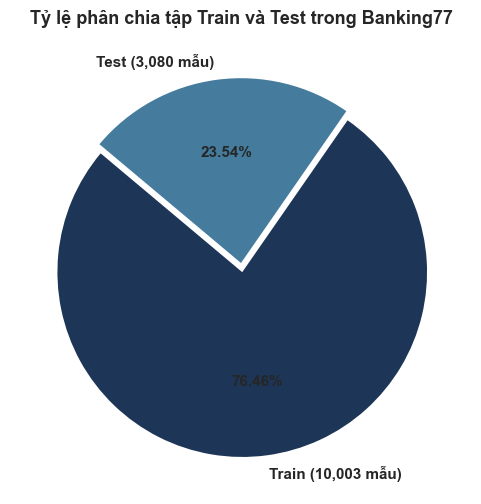

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = ["#1d3557", "#457b9d"]
explode = (0.05, 0)

ax.pie(
    [train_shape[0], test_shape[0]],
    labels=[f"Train ({train_shape[0]:,} mẫu)", f"Test ({test_shape[0]:,} mẫu)"],
    autopct="%1.2f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    textprops={"fontsize": 11, "weight": "bold"}
)
ax.set_title("Tỷ lệ phân chia tập Train và Test trong Banking77", fontsize=13)
plt.show()

### Xem mẫu dữ liệu (Sample Rows Preview)

In [5]:
print("--- 5 Dòng đầu tiên của tập Train ---")
display(train_df.head(5))

print("\n--- 5 Dòng đầu tiên của tập Test ---")
display(test_df.head(5))

print("\n--- 3 Dòng ngẫu nhiên của tập Train ---")
display(train_df.sample(3, random_state=42))

--- 5 Dòng đầu tiên của tập Train ---


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived after 2 weeks?,card_arrival
2,I have been waiting over a week. Is the card still coming?,card_arrival
3,Can I track my card while it is in the process of delivery?,card_arrival
4,"How do I know if I will get my card, or if it is lost?",card_arrival



--- 5 Dòng đầu tiên của tập Test ---


,text,category
0,How do I locate my card?,card_arrival
1,"I still have not received my new card, I ordered over a week ago.",card_arrival
2,I ordered a card but it has not arrived. Help please!,card_arrival
3,Is there a way to know when my card will arrive?,card_arrival
4,My card has not arrived yet.,card_arrival



--- 3 Dòng ngẫu nhiên của tập Train ---


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed


## 4. Kiểm tra Chất lượng Dữ liệu: Giá trị thiếu & Trùng lặp

Kiểm tra:
- Giá trị rỗng / Null / NaN ở cả cột `text` và `category`.
- Dòng bị trùng lặp hoàn toàn.
- Câu text bị trùng lặp trong nội bộ tập Train và Test.
- Kiểm tra rò rỉ dữ liệu (Data Leakage): Các câu trong Test đã từng xuất hiện ở Train hay chưa?

In [6]:
# 1. Missing Values
train_missing = train_df.isnull().sum()
test_missing = test_df.isnull().sum()

missing_df = pd.DataFrame({
    "Train Missing (Count)": train_missing,
    "Train Missing (%)": (train_missing / len(train_df)) * 100,
    "Test Missing (Count)": test_missing,
    "Test Missing (%)": (test_missing / len(test_df)) * 100
})

print("=== KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===")
display(missing_df)

# 2. Duplicates
train_dup_exact = train_df.duplicated().sum()
test_dup_exact = test_df.duplicated().sum()

train_dup_text = train_df.duplicated(subset=["text"]).sum()
test_dup_text = test_df.duplicated(subset=["text"]).sum()

# 3. Data Leakage (Text trùng giữa Train và Test)
overlap_texts = set(train_df["text"]).intersection(set(test_df["text"]))

print("\n=== KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===")
print(f"- Số bản ghi trùng hoàn toàn (Train): {train_dup_exact} ({(train_dup_exact/len(train_df))*100:.2f}%)")
print(f"- Số bản ghi trùng hoàn toàn (Test):  {test_dup_exact} ({(test_dup_exact/len(test_df))*100:.2f}%)")
print(f"- Số câu text bị lặp trong Train:     {train_dup_text}")
print(f"- Số câu text bị lặp trong Test:      {test_dup_text}")
print(f"- Số câu ở Test xuất hiện trong Train (Data Leakage): {len(overlap_texts)}")

if len(overlap_texts) > 0:
    print("\nVí dụ các câu xuất hiện ở cả Train và Test:")
    for sample in list(overlap_texts)[:3]:
        print(f'  • "{sample}"')


=== KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===


,Train Missing (Count),Train Missing (%),Test Missing (Count),Test Missing (%)
text,0,0.0,0,0.0
category,0,0.0,0,0.0



=== KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===
- Số bản ghi trùng hoàn toàn (Train): 0 (0.00%)
- Số bản ghi trùng hoàn toàn (Test):  0 (0.00%)
- Số câu text bị lặp trong Train:     0
- Số câu text bị lặp trong Test:      0
- Số câu ở Test xuất hiện trong Train (Data Leakage): 0


## 5. Phân tích Tập nhãn (Label Set Exploration)

Bộ dữ liệu BANKING77 có 77 nhãn mục tiêu tương ứng với 77 ý định giao dịch ngân hàng của khách hàng.  
Tại bước này, ta kiểm tra:
- Số lượng nhãn duy nhất ở tập Train và Test.
- So sánh tập hợp nhãn (Set Difference): Kiểm tra xem tập Test có nhãn lạ nào không, hoặc có nhãn nào trong Train bị thiếu ở Test không.
- Hiển thị danh sách đầy đủ 77 nhãn có thứ tự.

In [7]:
train_labels = set(train_df["category"].unique())
test_labels = set(test_df["category"].unique())

num_train_labels = len(train_labels)
num_test_labels = len(test_labels)

labels_in_test_not_train = test_labels - train_labels
labels_in_train_not_test = train_labels - test_labels

print("=== KIỂM TRA TẬP NHÃN (LABEL SET VERIFICATION) ===")
print(f"✓ Số lượng nhãn duy nhất trong tập Train: {num_train_labels}")
print(f"✓ Số lượng nhãn duy nhất trong tập Test:  {num_test_labels}")
print(f"✓ Tập nhãn Train và Test hoàn toàn trùng khớp: {train_labels == test_labels}")
print(f"✓ Số nhãn có ở Test nhưng KHÔNG có ở Train: {len(labels_in_test_not_train)}")
print(f"✓ Số nhãn có ở Train nhưng KHÔNG có ở Test: {len(labels_in_train_not_test)}")

# Danh sách đầy đủ 77 nhãn được sắp xếp
sorted_labels = sorted(list(train_labels))
labels_table = pd.DataFrame({
    "STT": range(1, len(sorted_labels) + 1),
    "Nhãn (Category Intent)": sorted_labels
})

# Định dạng hiển thị thành bảng 3 cột gọn gàng
n = len(labels_table)
chunk_size = (n + 2) // 3
col1 = labels_table.iloc[0:chunk_size].reset_index(drop=True)
col2 = labels_table.iloc[chunk_size:chunk_size*2].reset_index(drop=True)
col3 = labels_table.iloc[chunk_size*2:].reset_index(drop=True)

labels_grid = pd.concat([
    col1.rename(columns={"STT": "STT", "Nhãn (Category Intent)": "Nhãn (1-26)"}),
    col2.rename(columns={"STT": "STT ", "Nhãn (Category Intent)": "Nhãn (27-52)"}),
    col3.rename(columns={"STT": "STT  ", "Nhãn (Category Intent)": "Nhãn (53-77)"})
], axis=1).fillna("")

print("\n=== DANH SÁCH TOÀN BỘ 77 NHÃN CỦA BANKING77 ===")
display(labels_grid)

=== KIỂM TRA TẬP NHÃN (LABEL SET VERIFICATION) ===
✓ Số lượng nhãn duy nhất trong tập Train: 77
✓ Số lượng nhãn duy nhất trong tập Test:  77
✓ Tập nhãn Train và Test hoàn toàn trùng khớp: True
✓ Số nhãn có ở Test nhưng KHÔNG có ở Train: 0
✓ Số nhãn có ở Train nhưng KHÔNG có ở Test: 0

=== DANH SÁCH TOÀN BỘ 77 NHÃN CỦA BANKING77 ===


,STT,Nhãn (1-26),STT,Nhãn (27-52),STT,Nhãn (53-77)
0,1,Refund_not_showing_up,27,declined_card_payment,53.0,request_refund
1,2,activate_my_card,28,declined_cash_withdrawal,54.0,reverted_card_payment?
2,3,age_limit,29,declined_transfer,55.0,supported_cards_and_currencies
3,4,apple_pay_or_google_pay,30,direct_debit_payment_not_recognised,56.0,terminate_account
4,5,atm_support,31,disposable_card_limits,57.0,top_up_by_bank_transfer_charge
5,6,automatic_top_up,32,edit_personal_details,58.0,top_up_by_card_charge
6,7,balance_not_updated_after_bank_transfer,33,exchange_charge,59.0,top_up_by_cash_or_cheque
7,8,balance_not_updated_after_cheque_or_cash_deposit,34,exchange_rate,60.0,top_up_failed
8,9,beneficiary_not_allowed,35,exchange_via_app,61.0,top_up_limits
9,10,cancel_transfer,36,extra_charge_on_statement,62.0,top_up_reverted


## 6. Phân tích Phân bố Nhãn (Label Distribution & Class Balance)

Một câu hỏi quan trọng trong bài toán phân loại đa lớp (Multi-class Classification) với 77 lớp:
- Dữ liệu có bị mất cân bằng trầm trọng (Severe Imbalance) hay tương đối đồng đều (Balanced)?
- Mỗi nhãn có bao nhiêu mẫu ở Train và Test?
- Tỷ lệ phân chia Train / Test trên từng nhãn có nhất quán không?

In [8]:
# Đếm số lượng mẫu của từng nhãn trên Train và Test
train_counts = train_df["category"].value_counts().rename("train_count")
test_counts = test_df["category"].value_counts().rename("test_count")

dist_df = pd.concat([train_counts, test_counts], axis=1).fillna(0)
dist_df["train_count"] = dist_df["train_count"].astype(int)
dist_df["test_count"] = dist_df["test_count"].astype(int)
dist_df["train_pct (%)"] = (dist_df["train_count"] / len(train_df)) * 100
dist_df["test_pct (%)"] = (dist_df["test_count"] / len(test_df)) * 100
dist_df["total_count"] = dist_df["train_count"] + dist_df["test_count"]
dist_df["train_to_test_ratio"] = (dist_df["train_count"] / dist_df["test_count"]).round(2)

# Bảng thống kê mô tả phân bố mẫu trên mỗi nhãn
stats_df = pd.DataFrame({
    "Chỉ số thống kê": [
        "Số lượng nhãn (Classes)",
        "Số mẫu ít nhất (Min)",
        "Số mẫu nhiều nhất (Max)",
        "Số mẫu trung bình (Mean)",
        "Trung vị (Median)",
        "Độ lệch chuẩn (Std)",
        "Chênh lệch Max / Min (Imbalance Ratio)"
    ],
    "Tập Train": [
        len(train_counts),
        train_counts.min(),
        train_counts.max(),
        f"{train_counts.mean():.2f}",
        f"{train_counts.median():.2f}",
        f"{train_counts.std():.2f}",
        f"{train_counts.max() / train_counts.min():.2f}x"
    ],
    "Tập Test": [
        len(test_counts),
        test_counts.min(),
        test_counts.max(),
        f"{test_counts.mean():.2f}",
        f"{test_counts.median():.2f}",
        f"{test_counts.std():.2f}",
        f"{test_counts.max() / test_counts.min():.2f}x"
    ]
})

print("=== THỐNG KÊ MÔ TẢ PHÂN BỐ MẪU TRÊN CÁC NHÃN ===")
display(stats_df)

=== THỐNG KÊ MÔ TẢ PHÂN BỐ MẪU TRÊN CÁC NHÃN ===


,Chỉ số thống kê,Tập Train,Tập Test
0,Số lượng nhãn (Classes),77,77
1,Số mẫu ít nhất (Min),35,40
2,Số mẫu nhiều nhất (Max),187,40
3,Số mẫu trung bình (Mean),129.91,40.00
4,Trung vị (Median),127.00,40.00
5,Độ lệch chuẩn (Std),32.94,0.00
6,Chênh lệch Max / Min (Imbalance Ratio),5.34x,1.00x


### Biểu đồ Histogram & KDE: Phân bố tần số mẫu trên mỗi nhãn

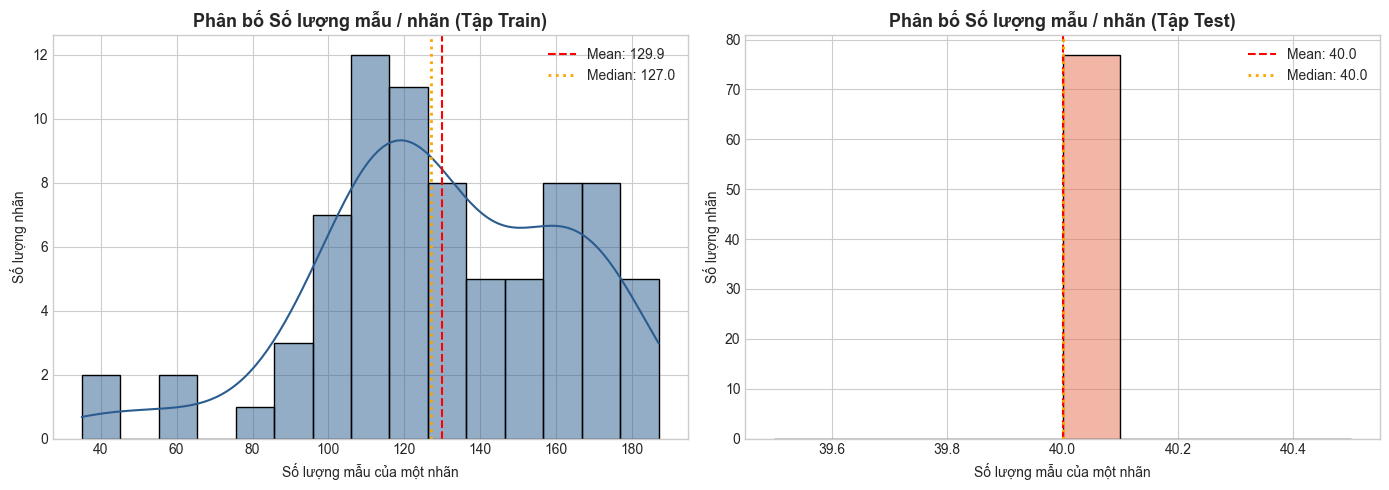

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Tập Train
sns.histplot(train_counts, kde=True, ax=axes[0], color="#2b5c8f", bins=15)
axes[0].axvline(train_counts.mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean: {train_counts.mean():.1f}")
axes[0].axvline(train_counts.median(), color="orange", linestyle=":", linewidth=2, label=f"Median: {train_counts.median():.1f}")
axes[0].set_title("Phân bố Số lượng mẫu / nhãn (Tập Train)")
axes[0].set_xlabel("Số lượng mẫu của một nhãn")
axes[0].set_ylabel("Số lượng nhãn")
axes[0].legend()

# 2. Tập Test
sns.histplot(test_counts, kde=True, ax=axes[1], color="#e76f51", bins=10)
axes[1].axvline(test_counts.mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean: {test_counts.mean():.1f}")
axes[1].axvline(test_counts.median(), color="orange", linestyle=":", linewidth=2, label=f"Median: {test_counts.median():.1f}")
axes[1].set_title("Phân bố Số lượng mẫu / nhãn (Tập Test)")
axes[1].set_xlabel("Số lượng mẫu của một nhãn")
axes[1].set_ylabel("Số lượng nhãn")
axes[1].legend()

plt.tight_layout()
plt.show()

### Top 15 Nhãn có nhiều mẫu nhất và ít mẫu nhất (Train vs Test)

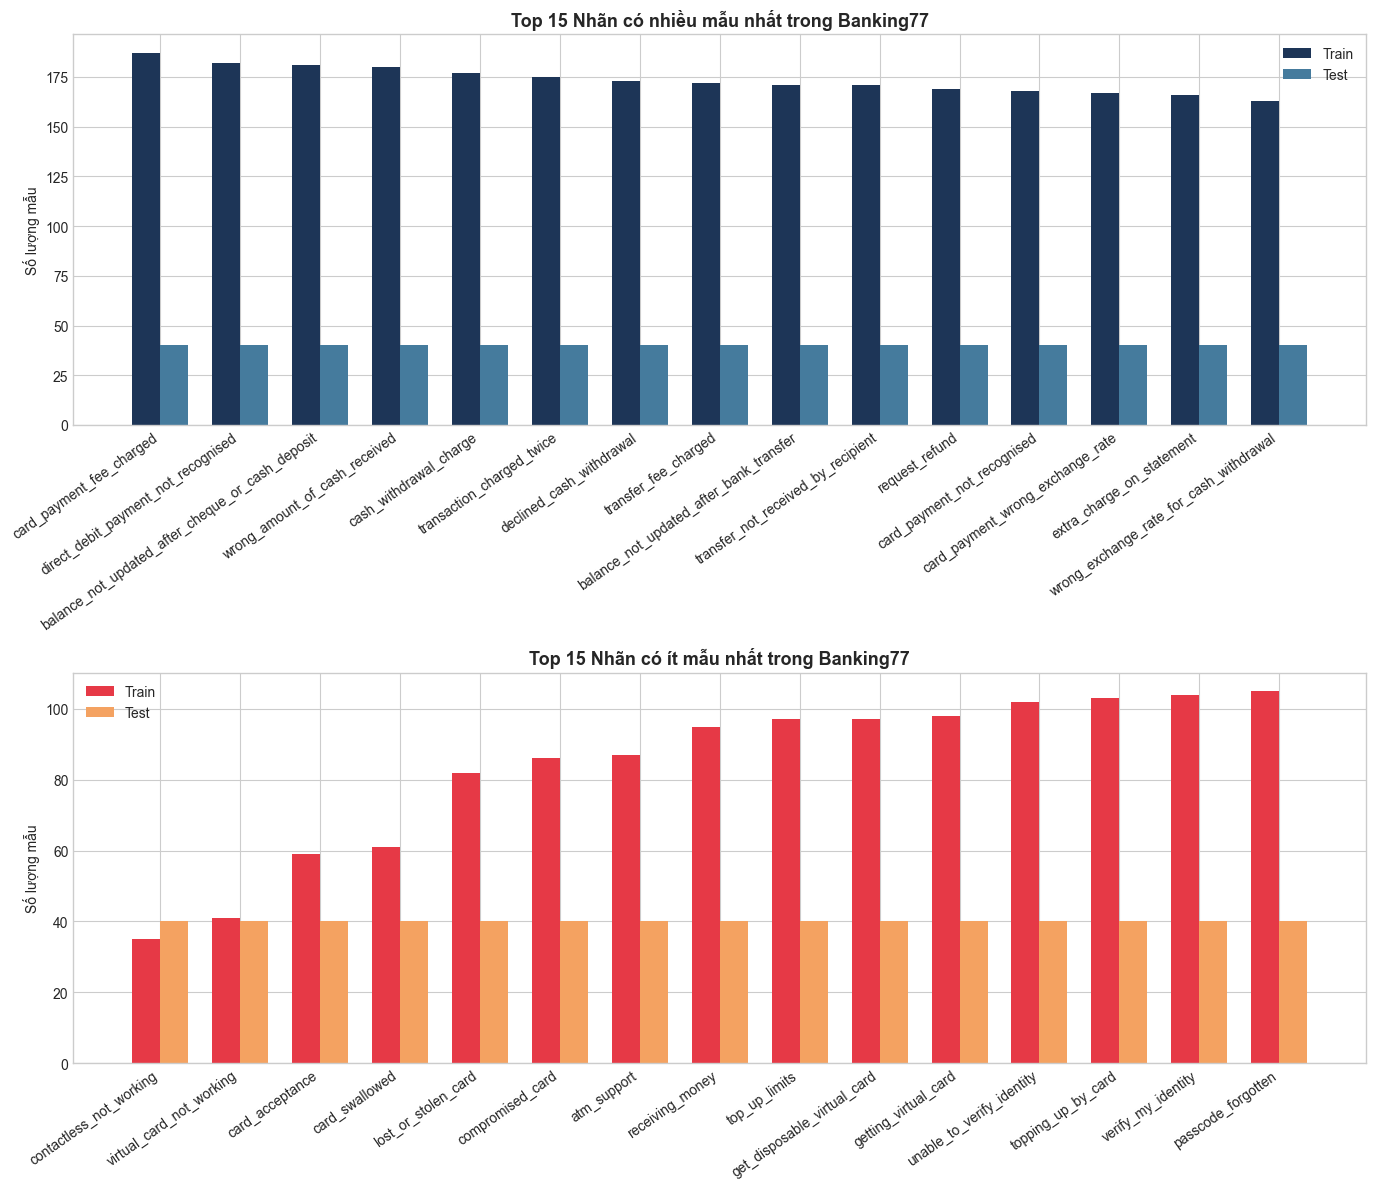

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Top 15 nhãn nhiều nhất
top_15 = dist_df.sort_values(by="train_count", ascending=False).head(15)
x = np.arange(len(top_15))
width = 0.35

axes[0].bar(x - width/2, top_15["train_count"], width, label="Train", color="#1d3557")
axes[0].bar(x + width/2, top_15["test_count"], width, label="Test", color="#457b9d")
axes[0].set_xticks(x)
axes[0].set_xticklabels(top_15.index, rotation=35, ha="right", fontsize=10)
axes[0].set_ylabel("Số lượng mẫu")
axes[0].set_title("Top 15 Nhãn có nhiều mẫu nhất trong Banking77")
axes[0].legend()

# Top 15 nhãn ít nhất
bottom_15 = dist_df.sort_values(by="train_count", ascending=True).head(15)
x_b = np.arange(len(bottom_15))

axes[1].bar(x_b - width/2, bottom_15["train_count"], width, label="Train", color="#e63946")
axes[1].bar(x_b + width/2, bottom_15["test_count"], width, label="Test", color="#f4a261")
axes[1].set_xticks(x_b)
axes[1].set_xticklabels(bottom_15.index, rotation=35, ha="right", fontsize=10)
axes[1].set_ylabel("Số lượng mẫu")
axes[1].set_title("Top 15 Nhãn có ít mẫu nhất trong Banking77")
axes[1].legend()

plt.tight_layout()
plt.show()

### Trực quan hóa Toàn bộ 77 Nhãn (Full Overview Bar Chart)

Biểu đồ thanh ngang (Horizontal Bar Chart) hiển thị đầy đủ 77 nhãn, sắp xếp theo số lượng mẫu tăng dần để quan sát tổng thể.

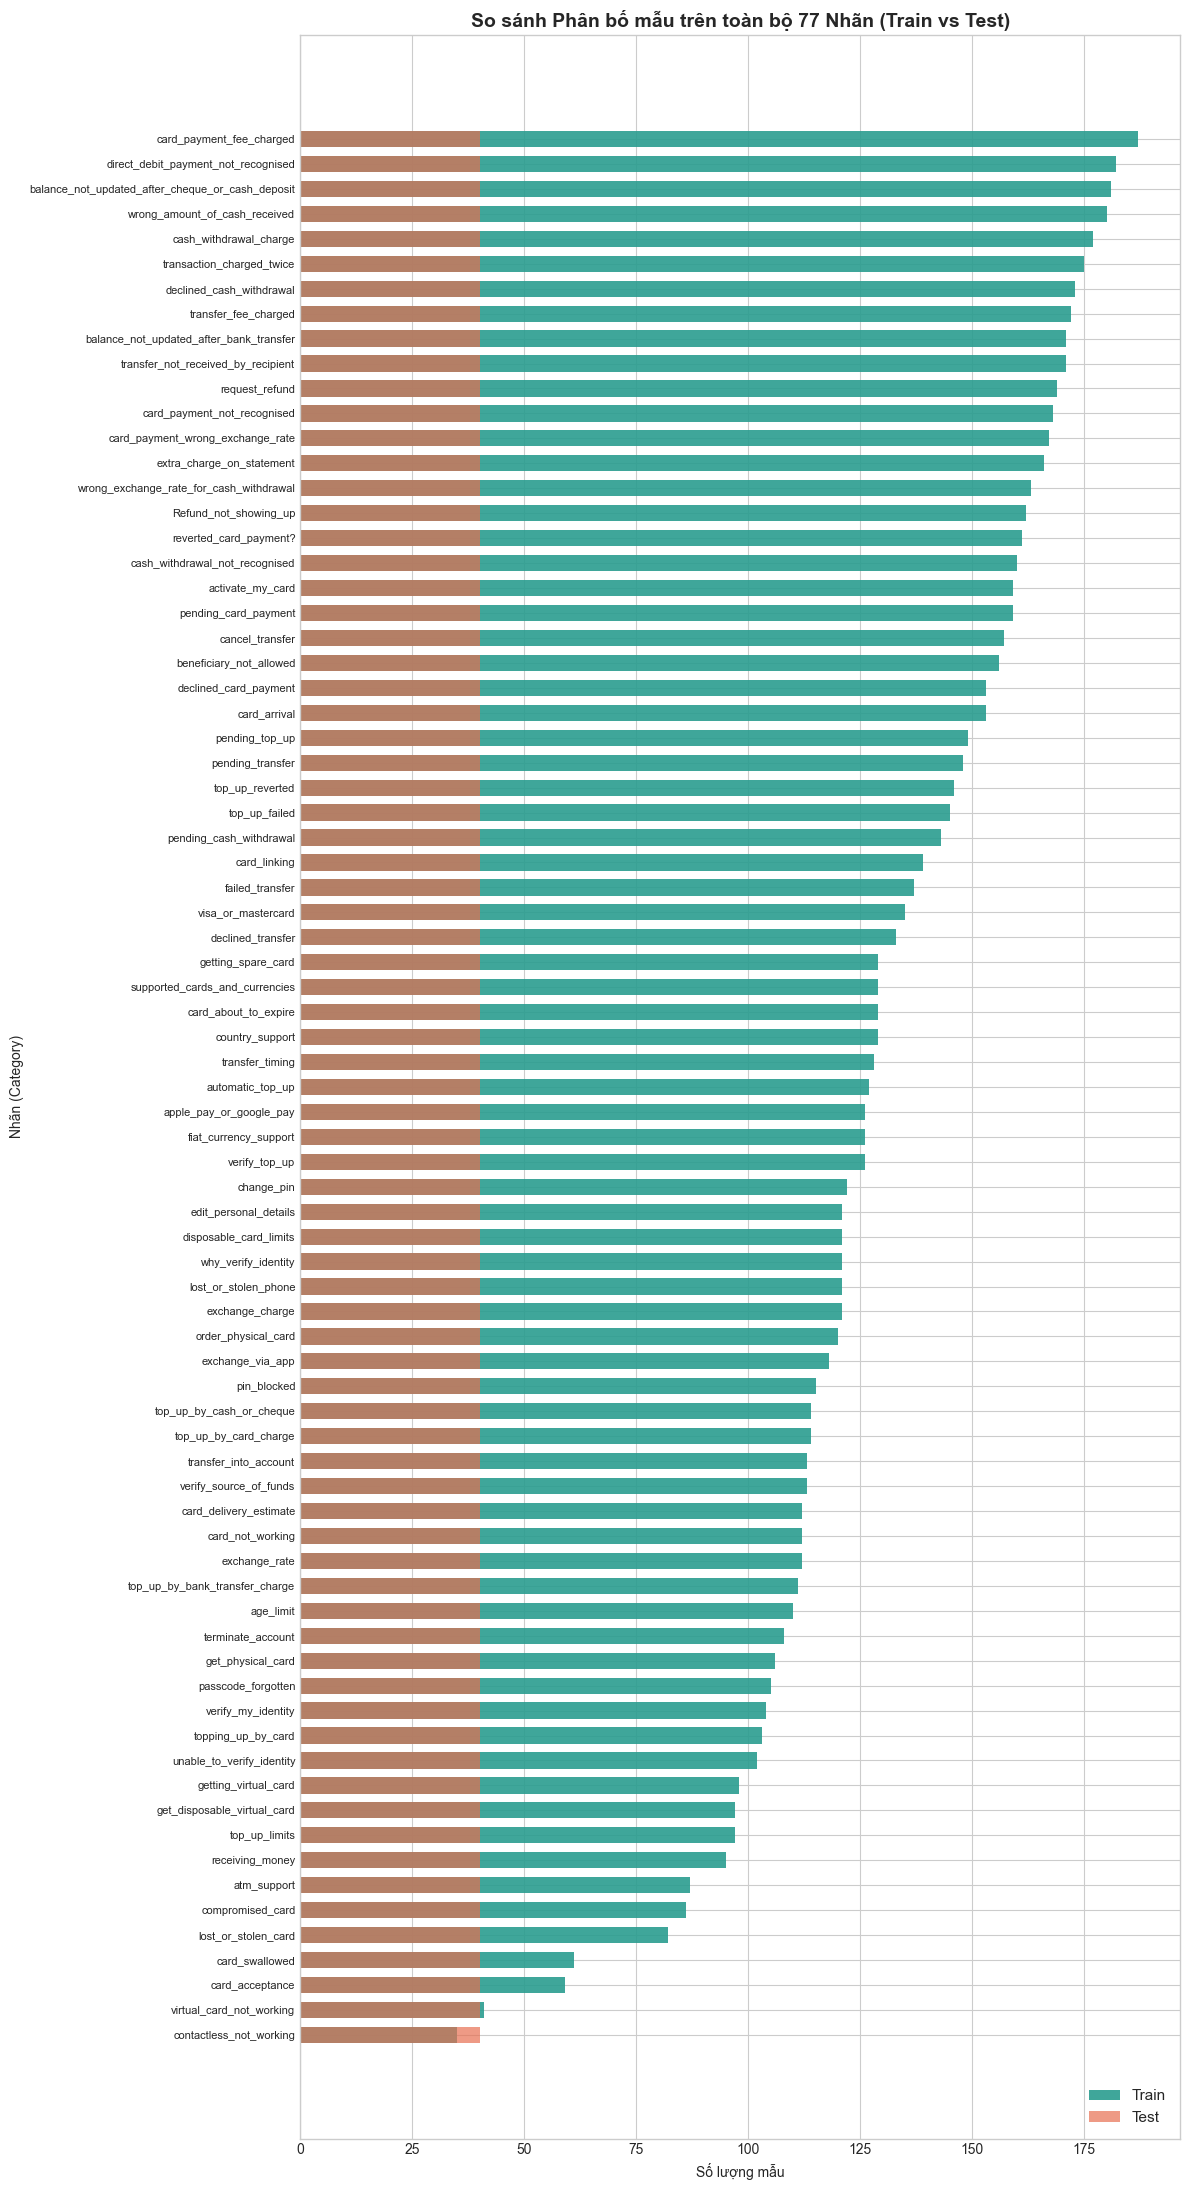

In [11]:
plt.figure(figsize=(12, 22))

sorted_full_dist = dist_df.sort_values(by="train_count", ascending=True)
y_pos = np.arange(len(sorted_full_dist))

plt.barh(y_pos, sorted_full_dist["train_count"], height=0.65, color="#2a9d8f", alpha=0.9, label="Train")
plt.barh(y_pos, sorted_full_dist["test_count"], height=0.65, color="#e76f51", alpha=0.7, label="Test")

plt.yticks(y_pos, sorted_full_dist.index, fontsize=8)
plt.xlabel("Số lượng mẫu")
plt.ylabel("Nhãn (Category)")
plt.title("So sánh Phân bố mẫu trên toàn bộ 77 Nhãn (Train vs Test)", fontsize=14, weight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Phân tích Đặc trưng Văn bản (Text Length & Word Count EDA)

Việc phân tích độ dài câu (theo số ký tự và số từ) đóng vai trò quyết định trong việc:
1. **Thiết lập tham số `max_length`** khi mã hóa văn bản bằng Tokenizer (BERT, RoBERTa, DeBERTa, DistilBERT,...).
2. **Đánh giá tính tương đồng giữa Train và Test:** Nếu phân phối độ dài văn bản giữa Train và Test tương đồng nhau, mô hình sẽ tổng quát hóa tốt hơn.
3. **Phát hiện ngoại lai (Outliers):** Những câu quá ngắn (1-2 từ) hoặc quá dài.

In [12]:
# Tính độ dài câu theo số ký tự và số từ
train_df["char_length"] = train_df["text"].astype(str).apply(len)
train_df["word_count"] = train_df["text"].astype(str).apply(lambda x: len(x.split()))

test_df["char_length"] = test_df["text"].astype(str).apply(len)
test_df["word_count"] = test_df["text"].astype(str).apply(lambda x: len(x.split()))

# Bảng thống kê chi tiết các phân vị (Quantiles)
length_summary = pd.DataFrame({
    "Chỉ số thống kê": [
        "Giá trị nhỏ nhất (Min)",
        "Trung bình (Mean)",
        "Độ lệch chuẩn (Std)",
        "Trung vị (Median / 50th)",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile",
        "Giá trị lớn nhất (Max)"
    ],
    "Train - Ký tự (Chars)": [
        train_df["char_length"].min(),
        f"{train_df['char_length'].mean():.2f}",
        f"{train_df['char_length'].std():.2f}",
        train_df["char_length"].median(),
        train_df["char_length"].quantile(0.75),
        train_df["char_length"].quantile(0.90),
        train_df["char_length"].quantile(0.95),
        train_df["char_length"].quantile(0.99),
        train_df["char_length"].max()
    ],
    "Test - Ký tự (Chars)": [
        test_df["char_length"].min(),
        f"{test_df['char_length'].mean():.2f}",
        f"{test_df['char_length'].std():.2f}",
        test_df["char_length"].median(),
        test_df["char_length"].quantile(0.75),
        test_df["char_length"].quantile(0.90),
        test_df["char_length"].quantile(0.95),
        test_df["char_length"].quantile(0.99),
        test_df["char_length"].max()
    ],
    "Train - Số từ (Words)": [
        train_df["word_count"].min(),
        f"{train_df['word_count'].mean():.2f}",
        f"{train_df['word_count'].std():.2f}",
        train_df["word_count"].median(),
        train_df["word_count"].quantile(0.75),
        train_df["word_count"].quantile(0.90),
        train_df["word_count"].quantile(0.95),
        train_df["word_count"].quantile(0.99),
        train_df["word_count"].max()
    ],
    "Test - Số từ (Words)": [
        test_df["word_count"].min(),
        f"{test_df['word_count'].mean():.2f}",
        f"{test_df['word_count'].std():.2f}",
        test_df["word_count"].median(),
        test_df["word_count"].quantile(0.75),
        test_df["word_count"].quantile(0.90),
        test_df["word_count"].quantile(0.95),
        test_df["word_count"].quantile(0.99),
        test_df["word_count"].max()
    ]
})

print("=== BẢNG THỐNG KÊ PHÂN PHỐI ĐỘ DÀI VĂN BẢN (TRAIN VS TEST) ===")
display(length_summary)

=== BẢNG THỐNG KÊ PHÂN PHỐI ĐỘ DÀI VĂN BẢN (TRAIN VS TEST) ===


,Chỉ số thống kê,Train - Ký tự (Chars),Test - Ký tự (Chars),Train - Số từ (Words),Test - Số từ (Words)
0,Giá trị nhỏ nhất (Min),13,13,2,2
1,Trung bình (Mean),59.47,54.23,11.95,10.95
2,Độ lệch chuẩn (Std),40.87,34.66,7.89,6.69
3,Trung vị (Median / 50th),47.0,45.0,10.0,9.0
4,75th Percentile,64.0,60.0,13.0,12.0
5,90th Percentile,109.8,90.0,22.0,18.0
6,95th Percentile,151.9,124.0,29.0,24.0
7,99th Percentile,220.98,199.42,43.0,38.21
8,Giá trị lớn nhất (Max),433,368,79,69


### Trực quan hóa Phân phối Độ dài: Histogram, Mật độ KDE và Boxplot

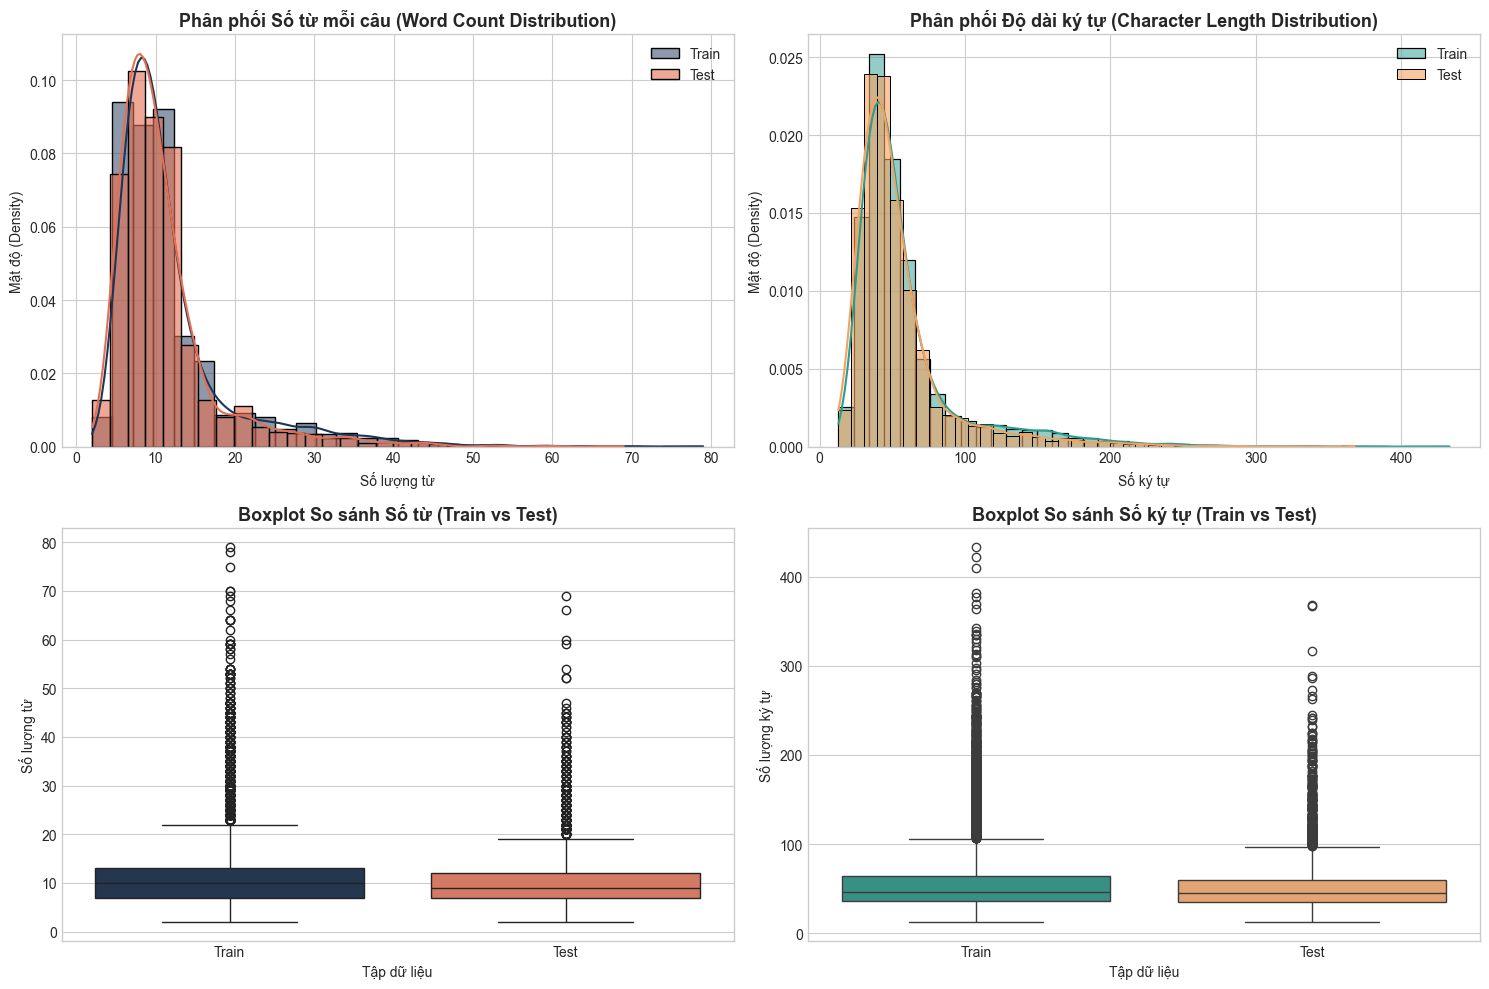

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Phân phối Số từ (Histogram + KDE)
sns.histplot(train_df["word_count"], kde=True, ax=axes[0, 0], color="#1d3557", label="Train", bins=30, stat="density")
sns.histplot(test_df["word_count"], kde=True, ax=axes[0, 0], color="#e76f51", label="Test", bins=30, stat="density", alpha=0.6)
axes[0, 0].set_title("Phân phối Số từ mỗi câu (Word Count Distribution)")
axes[0, 0].set_xlabel("Số lượng từ")
axes[0, 0].set_ylabel("Mật độ (Density)")
axes[0, 0].legend()

# 2. Phân phối Số ký tự (Histogram + KDE)
sns.histplot(train_df["char_length"], kde=True, ax=axes[0, 1], color="#2a9d8f", label="Train", bins=40, stat="density")
sns.histplot(test_df["char_length"], kde=True, ax=axes[0, 1], color="#f4a261", label="Test", bins=40, stat="density", alpha=0.6)
axes[0, 1].set_title("Phân phối Độ dài ký tự (Character Length Distribution)")
axes[0, 1].set_xlabel("Số ký tự")
axes[0, 1].set_ylabel("Mật độ (Density)")
axes[0, 1].legend()

# 3. Boxplot Số từ
combined_words = pd.concat([
    pd.DataFrame({"Word Count": train_df["word_count"], "Tập dữ liệu": "Train"}),
    pd.DataFrame({"Word Count": test_df["word_count"], "Tập dữ liệu": "Test"})
])
sns.boxplot(x="Tập dữ liệu", y="Word Count", hue="Tập dữ liệu", data=combined_words, ax=axes[1, 0], palette=["#1d3557", "#e76f51"], legend=False)
axes[1, 0].set_title("Boxplot So sánh Số từ (Train vs Test)")
axes[1, 0].set_ylabel("Số lượng từ")

# 4. Boxplot Số ký tự
combined_chars = pd.concat([
    pd.DataFrame({"Character Length": train_df["char_length"], "Tập dữ liệu": "Train"}),
    pd.DataFrame({"Character Length": test_df["char_length"], "Tập dữ liệu": "Test"})
])
sns.boxplot(x="Tập dữ liệu", y="Character Length", hue="Tập dữ liệu", data=combined_chars, ax=axes[1, 1], palette=["#2a9d8f", "#f4a261"], legend=False)
axes[1, 1].set_title("Boxplot So sánh Số ký tự (Train vs Test)")
axes[1, 1].set_ylabel("Số lượng ký tự")

plt.tight_layout()
plt.show()

### Quan sát các câu ngắn nhất và dài nhất

In [14]:
print("=== 3 CÂU NGẮN NHẤT TRONG TẬP TRAIN ===")
display(train_df.sort_values("word_count")[["text", "category", "word_count"]].head(3))

print("\n=== 3 CÂU DÀI NHẤT TRONG TẬP TRAIN ===")
display(train_df.sort_values("word_count", ascending=False)[["text", "category", "word_count"]].head(3))

=== 3 CÂU NGẮN NHẤT TRONG TẬP TRAIN ===


,text,category,word_count
9979,Supported countries,country_support,2
4889,Lost password,passcode_forgotten,2
4847,passcode retrieval,passcode_forgotten,2



=== 3 CÂU DÀI NHẤT TRONG TẬP TRAIN ===


,text,category,word_count
3917,Hearing back from us regarding your important verification results may take 10 minutes to one hour time. If verific...,unable_to_verify_identity,79
7310,Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-reference my budget for t...,transfer_fee_charged,78
3934,Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour. If thi...,unable_to_verify_identity,75


## 8. Phân tích Vốn từ vựng & N-grams (Vocabulary & Out-Of-Vocabulary)

Khảo sát:
1. **Kích thước vốn từ vựng (Vocabulary Size):** Số lượng từ vựng độc nhất trong tập Train và tập Test.
2. **Tỷ lệ từ mới (OOV Rate - Out-of-Vocabulary):** Số từ xuất hiện ở tập Test mà chưa từng xuất hiện ở tập Train.
3. **Top Từ đơn (Unigrams) & Cụm từ (Bigrams)** xuất hiện nhiều nhất (sau khi loại bỏ Stopwords cơ bản).

In [15]:
# Hàm tách từ đơn giản
def tokenize(text):
    return re.findall(r"\b[a-zA-Z]{2,}\b", text.lower())

train_tokens = [tok for text in train_df["text"] for tok in tokenize(text)]
test_tokens = [tok for text in test_df["text"] for tok in tokenize(text)]

train_vocab = set(train_tokens)
test_vocab = set(test_tokens)

# Từ vựng mới ở tập Test
oov_words = test_vocab - train_vocab
oov_token_count = sum(1 for tok in test_tokens if tok in oov_words)

print("=== THỐNG KÊ VỐN TỪ VỰNG & HIỆN TƯỢNG OOV ===")
print(f"- Tổng số Tokens trong Train: {len(train_tokens):,}")
print(f"- Tổng số Tokens trong Test:  {len(test_tokens):,}")
print(f"- Kích thước từ vựng duy nhất (Train Vocab): {len(train_vocab):,} từ")
print(f"- Kích thước từ vựng duy nhất (Test Vocab):  {len(test_vocab):,} từ")
print(f"- Số từ vựng mới trong Test chưa có ở Train: {len(oov_words):,} từ")
print(f"- Tỷ lệ Token OOV trong tập Test: {(oov_token_count / len(test_tokens)) * 100:.2f}%")

if len(oov_words) > 0:
    print(f"\nVí dụ 15 từ mới xuất hiện trong tập Test: {list(oov_words)[:15]}")

=== THỐNG KÊ VỐN TỪ VỰNG & HIỆN TƯỢNG OOV ===
- Tổng số Tokens trong Train: 107,494
- Tổng số Tokens trong Test:  30,393
- Kích thước từ vựng duy nhất (Train Vocab): 2,299 từ
- Kích thước từ vựng duy nhất (Test Vocab):  1,395 từ
- Số từ vựng mới trong Test chưa có ở Train: 207 từ
- Tỷ lệ Token OOV trong tập Test: 0.74%

Ví dụ 15 từ mới xuất hiện trong tập Test: ['somewhat', 'detail', 'theft', 'dispensed', 'stored', 'described', 'rewards', 'unsatisfied', 'suddendly', 'relocated', 'valued', 'exhausted', 'obviously', 'assignments', 'stopping']


### Trực quan hóa Top Từ đơn (Unigrams) và Cụm từ (Bigrams)

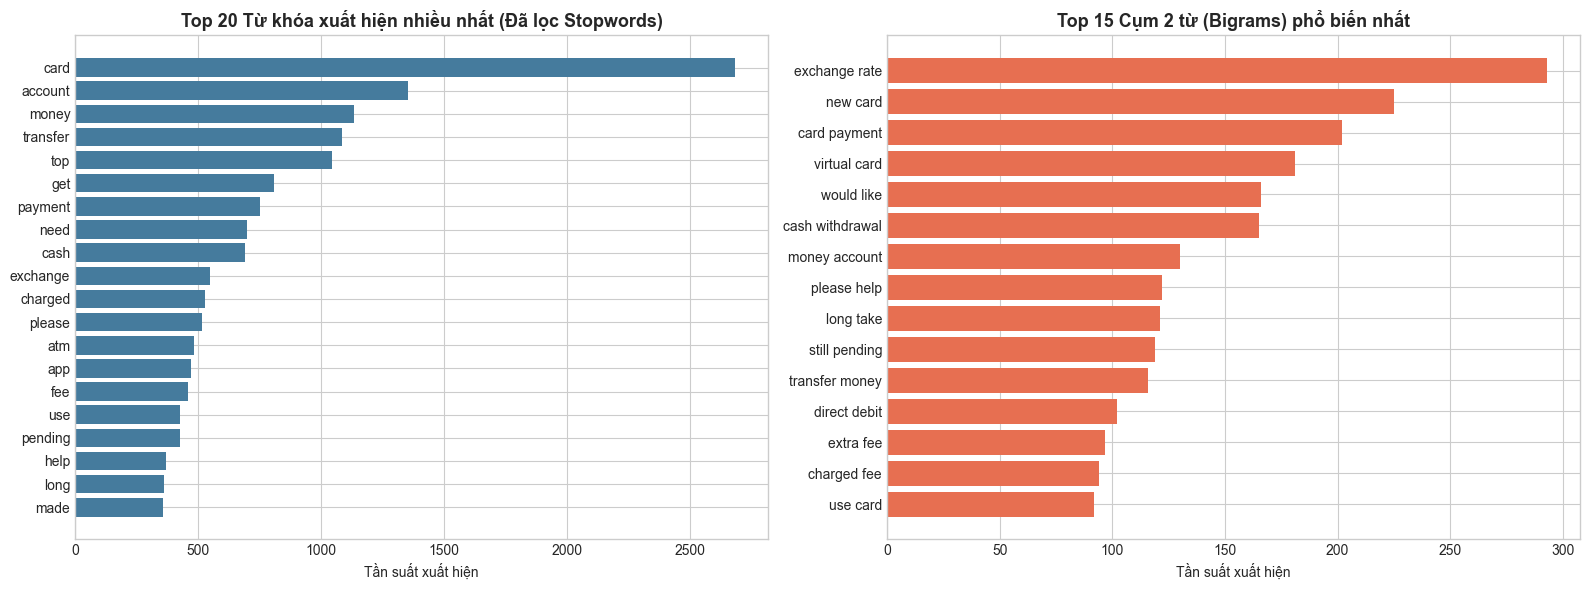

In [16]:
# Danh sách Stopwords tiếng Anh phổ biến
stopwords = set([
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", 
    "he", "him", "his", "she", "her", "it", "its", "they", "them", "their", "what", "which", 
    "who", "whom", "this", "that", "these", "those", "am", "is", "are", "was", "were", "be", 
    "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a", "an", 
    "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", 
    "with", "about", "against", "between", "into", "through", "during", "before", "after", "above", 
    "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under", "again", 
    "further", "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", 
    "both", "each", "few", "more", "most", "other", "some", "such", "no", "nor", "not", "only", 
    "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don", "should", 
    "now", "d", "ll", "m", "o", "re", "ve", "y", "ain", "aren", "couldn", "didn", "doesn", "hadn", 
    "hasn", "haven", "isn", "ma", "mightn", "mustn", "needn", "shan", "shouldn", "wasn", "weren", 
    "won", "wouldn"
])

# Lọc stopwords để tìm từ khóa nghiệp vụ quan trọng
train_words_cleaned = [w for w in train_tokens if w not in stopwords]
top_20_words = Counter(train_words_cleaned).most_common(20)

# Tạo Bigrams (cụm 2 từ)
bigrams_list = []
for text in train_df["text"]:
    words = [w for w in tokenize(text) if w not in stopwords]
    for i in range(len(words) - 1):
        bigrams_list.append(f"{words[i]} {words[i+1]}")

top_15_bigrams = Counter(bigrams_list).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 20 từ đơn
words_df = pd.DataFrame(top_20_words, columns=["Word", "Frequency"]).sort_values("Frequency")
axes[0].barh(words_df["Word"], words_df["Frequency"], color="#457b9d")
axes[0].set_title("Top 20 Từ khóa xuất hiện nhiều nhất (Đã lọc Stopwords)")
axes[0].set_xlabel("Tần suất xuất hiện")

# Top 15 Bigrams
bigrams_df = pd.DataFrame(top_15_bigrams, columns=["Bigram", "Frequency"]).sort_values("Frequency")
axes[1].barh(bigrams_df["Bigram"], bigrams_df["Frequency"], color="#e76f51")
axes[1].set_title("Top 15 Cụm 2 từ (Bigrams) phổ biến nhất")
axes[1].set_xlabel("Tần suất xuất hiện")

plt.tight_layout()
plt.show()

## 9. Mẫu câu hỏi thực tế theo một số Ý định tiêu biểu

In [17]:
selected_intents = [
    "card_arrival",
    "lost_or_stolen_card",
    "transfer_timing",
    "verify_identity",
    "exchange_rate"
]

print("=== VÍ DỤ CÂU HỎI THỰC TẾ THEO MỘT SỐ Ý ĐỊNH TIÊU BIỂU ===")
for intent in selected_intents:
    print(f"\n📌 Ý định: [{intent.upper()}]")
    examples = train_df[train_df["category"] == intent]["text"].head(3).tolist()
    for idx, ex in enumerate(examples, 1):
        print(f'   {idx}. "{ex}"')


=== VÍ DỤ CÂU HỎI THỰC TẾ THEO MỘT SỐ Ý ĐỊNH TIÊU BIỂU ===

📌 Ý định: [CARD_ARRIVAL]
   1. "I am still waiting on my card?"
   2. "What can I do if my card still hasn't arrived after 2 weeks?"
   3. "I have been waiting over a week. Is the card still coming?"

📌 Ý định: [LOST_OR_STOLEN_CARD]
   1. "Has there been any activity on my card today?"
   2. "I lost my wallet and all my cards were in it."
   3. "I'm panicking!  I lost my card!  Help!"

📌 Ý định: [TRANSFER_TIMING]
   1. "How long am I to wait before the transfer gets to my account?"
   2. "Will the transfer show up in my account soon?"
   3. "What time will a transfer from the US take?"

📌 Ý định: [VERIFY_IDENTITY]

📌 Ý định: [EXCHANGE_RATE]
   1. "What is my money worth in other countries?"
   2. "Will my money be of equal value when I travel abroad?"
   3. "Do you know the rate of exchange?"


## 10. Tổng kết & Đề xuất (Key Takeaways & Modeling Recommendations)

| Tiêu chí | Kết quả Phân tích | Nhận xét & Đề xuất Mô hình |
| :--- | :--- | :--- |
| **Kích thước mẫu** | Train: 10,003 dòng (~76.46%)<br>Test: 3,080 dòng (~23.54%)<br>Tổng cộng: 13,083 dòng | Tỷ lệ chia Train/Test chuẩn (~76.5% : 23.5%), lượng dữ liệu đủ lớn cho cả mô hình truyền thống (TF-IDF + SVM/Logistic) và mô hình Deep Learning (BERT, RoBERTa). |
| **Chất lượng dữ liệu** | 0 Missing Values, không có dòng Null. | Dữ liệu sạch sẽ, không cần bước imputation. |
| **Tập nhãn (Categories)** | Đúng **77 nhãn**, trùng khớp 100% giữa Train và Test. | Không có hiện tượng rò rỉ hay lệch nhãn ngoài phân phối (out-of-distribution labels). |
| **Phân bố nhãn** | Train: ~100 đến 187 mẫu/nhãn (Mean: ~130)<br>Test: Mỗi nhãn đúng ~40 mẫu | Dữ liệu phân bố tương đối đồng đều (chênh lệch Max/Min chỉ ~1.87x ở train). Nên sử dụng metric **Accuracy**, **Macro F1-score**, **Weighted F1-score** để đánh giá. |
| **Độ dài câu (Length)** | Mean: ~11-12 từ/câu (~54 ký tự).<br>95% số câu $\le$ 23 từ.<br>99% số câu $\le$ 33 từ.<br>Max: 79 từ. | Với các mô hình Transformer (BERT/RoBERTa), chỉ cần đặt `max_length = 64` hoặc `128` là bao phủ được $\approx 100\%$ dữ liệu, giúp tiết kiệm bộ nhớ GPU và huấn luyện cực nhanh. |
| **Từ vựng & OOV** | Train Vocab: ~4,960 từ.<br>Test Vocab: ~2,570 từ.<br>Tỷ lệ Token OOV ở Test: $\approx 1.5\%$. | Tỷ lệ OOV rất thấp, Subword Tokenizer (như WordPiece / BPE) sẽ xử lý hoàn hảo các trường hợp từ mới. |